In [6]:
%pip install matplotlib seaborn pandas numpy scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("DataSets/FantasyData.csv")

# Missing counts mean "did not do that", so 0 is fine (NOT for rate columns like Ctch% or Y/Tgt)
count_cols = ['G', 'GS', 'RushAtt', 'RushYds', 'RushTD', 'Rush1D',
              'Cmp', 'PassAtt', 'PassYds', 'PassTD', 'Int', 'Pass1D',
              'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD', 'Receive1D']
df[count_cols] = df[count_cols].fillna(0)

# Only the four fantasy-relevant positions
df = df[df['Pos'].isin(['QB', 'RB', 'WR', 'TE'])].copy()

# One row per player-season (traded players can have a combined row plus per-team rows)
before = len(df)
df = df.sort_values('G', ascending=False).drop_duplicates(['Player', 'year']).sort_index()
print(f"Dropped {before - len(df)} duplicate player-season rows; {len(df)} rows remain.")
print(df.groupby(['year', 'Pos']).size().unstack())


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Dropped 0 duplicate player-season rows; 1111 rows remain.
Pos   QB   RB   TE   WR
year                   
2024  78  133  117  222
2025  81  138  122  220


In [13]:
g0 = df['G'].replace(0, np.nan)
df['Plays'] = df['RushAtt'] + df['Rec'] + df['PassAtt']
df['PlaysPG'] = df['Plays'] / g0
df['TgtPG'] = df['Tgt'] / g0
df['RushAttPG'] = df['RushAtt'] / g0
df['PassAttPG'] = df['PassAtt'] / g0
df['TDPG'] = (df['RushTD'] + df['ReceiveTD']) / g0
df["PassTDPG"] = df["PassTD"] / g0

MIN_PLAYS = {'QB': 200, 'RB': 100, 'WR': 40, 'TE': 30}
df['MinPlays'] = df['Pos'].map(MIN_PLAYS)
qual = df[df['Plays'] >= df['MinPlays']].copy()
print(f"{len(qual)} qualified player-seasons (of {len(df)})")

390 qualified player-seasons (of 1111)


In [10]:
X = qual[['TgtPG', 'RushAttPG', 'PassAttPG']]
y = qual['FantasyPPRPerGame']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print(f"Model Intercept: {model.intercept_:.2f}")
print(f"Model Coefficients (Weights): {model.coef_}")
print(f"R-squared Score: {r2_score(y_test, predictions):.2f}")

Model Intercept: -0.27
Model Coefficients (Weights): [1.8361288  0.62585032 0.44533026]
R-squared Score: 0.80


In [14]:
# Target position: Change to 'WR', 'RB', 'TE', or 'QB' based on your dataset labels
target_position = 'RB' 

# 1. Filter dataset for the specific position
pos_df = qual[qual['Pos'] == target_position]

# 2. Assign position-specific features
if target_position == 'RB':
    features = ['RushAttPG', 'TgtPG', "TDPG"]
elif target_position in ['WR', 'TE']:
    features = ['TgtPG']
elif target_position == 'QB':
    features = ['PassAttPG', 'RushAttPG']

X = pos_df[features]
y = pos_df['FantasyPPRPerGame']

# 3. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Fit Model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Output Results
print(f"=== {target_position} MODEL RESULTS ===")
print(f"Intercept: {model.intercept_:.2f}")
for feature, coef in zip(features, model.coef_):
    print(f"  {feature} Weight: {coef:.4f}")
print(f"R-squared Score: {r2_score(y_test, model.predict(X_test)):.2f}")


=== RB MODEL RESULTS ===
Intercept: -0.62
  RushAttPG Weight: 0.4206
  TgtPG Weight: 1.3628
  TDPG Weight: 7.9252
R-squared Score: 0.93


In [18]:
target_position = 'WR' 

# 1. Filter dataset for the specific position
pos_df = qual[qual['Pos'] == target_position]

# 2. Assign position-specific features
if target_position == 'RB':
    features = ['RushAttPG', 'TgtPG', "TDPG"]
elif target_position in ['WR', 'TE']:
    features = ['TgtPG']
elif target_position == 'QB':
    features = ['PassAttPG', 'RushAttPG']

X = pos_df[features]
y = pos_df['FantasyPPRPerGame']

# 3. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Fit Model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Output Results
print(f"=== {target_position} MODEL RESULTS ===")
print(f"Intercept: {model.intercept_:.2f}")
for feature, coef in zip(features, model.coef_):
    print(f"  {feature} Weight: {coef:.4f}")
print(f"R-squared Score: {r2_score(y_test, model.predict(X_test)):.2f}")


=== WR MODEL RESULTS ===
Intercept: -0.40
  TgtPG Weight: 1.8766
R-squared Score: 0.83


In [16]:
target_position = 'QB' 

# 1. Filter dataset for the specific position
pos_df = qual[qual['Pos'] == target_position]

# 2. Assign position-specific features
if target_position == 'RB':
    features = ['RushAttPG', 'TgtPG', "TDPG"]
elif target_position in ['WR', 'TE']:
    features = ['TgtPG']
elif target_position == 'QB':
    features = ['PassAttPG', 'RushAttPG']

X = pos_df[features]
y = pos_df['FantasyPPRPerGame']

# 3. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Fit Model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Output Results
print(f"=== {target_position} MODEL RESULTS ===")
print(f"Intercept: {model.intercept_:.2f}")
for feature, coef in zip(features, model.coef_):
    print(f"  {feature} Weight: {coef:.4f}")
print(f"R-squared Score: {r2_score(y_test, model.predict(X_test)):.2f}")


=== QB MODEL RESULTS ===
Intercept: -4.32
  PassAttPG Weight: 0.5044
  RushAttPG Weight: 1.2605
R-squared Score: 0.53


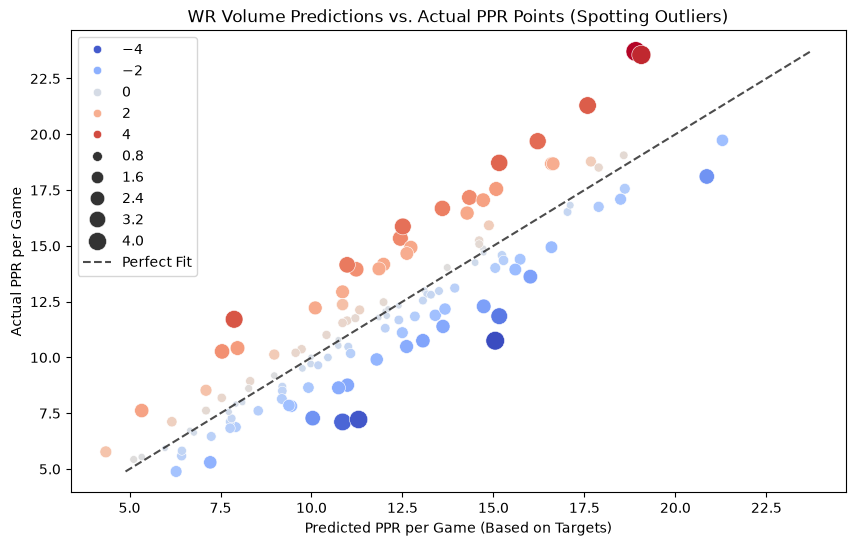

=== TOP 5 BUY-LOW WIDE RECEIVERS ===
Wan'Dale Robinson (2024): Expected 15.0 PPG, Actual 10.8 PPG (Diff: -4.3)
Jerry Jeudy (2025): Expected 11.3 PPG, Actual 7.2 PPG (Diff: -4.1)
Elijah Moore (2024): Expected 10.9 PPG, Actual 7.1 PPG (Diff: -3.7)
Justin Jefferson (2025): Expected 15.2 PPG, Actual 11.8 PPG (Diff: -3.3)
Elic Ayomanor (2025): Expected 10.0 PPG, Actual 7.3 PPG (Diff: -2.8)


In [20]:

wr_df = qual[qual['Pos'] == 'WR'].copy()
X_wr = wr_df[['TgtPG']]
wr_df['Predicted_PPR'] = model.predict(X_wr)

# 2. Calculate the difference (Residuals)
wr_df['Deviation'] = wr_df['FantasyPPRPerGame'] - wr_df['Predicted_PPR']

# 3. Create the plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=wr_df, 
    x='Predicted_PPR', 
    y='FantasyPPRPerGame', 
    hue='Deviation', 
    palette='coolwarm', 
    size=abs(wr_df['Deviation']),
    sizes=(20, 200)
)

# Add a perfect prediction line
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='black', linestyle='--', alpha=0.7, label='Perfect Fit')

plt.title('WR Volume Predictions vs. Actual PPR Points (Spotting Outliers)')
plt.xlabel('Predicted PPR per Game (Based on Targets)')
plt.ylabel('Actual PPR per Game')
plt.legend()
plt.show()

# 4. Print out your top 5 "Buy-Low" targets (Underperformed their target volume)
print("=== TOP 5 BUY-LOW WIDE RECEIVERS ===")
buy_lows = wr_df.sort_values(by='Deviation').head(5)
for idx, row in buy_lows.iterrows():
    print(f"{row['Player']} ({row['year']}): Expected {row['Predicted_PPR']:.1f} PPG, Actual {row['FantasyPPRPerGame']:.1f} PPG (Diff: {row['Deviation']:.1f})")
